## EN3160 Image Processing and Machine Vision
#### Assignment 03 on Neural Networks
#### Ratnayake R.M.S.H., 230548R
**GitHub Link:** [EN3160 Assignment 03](https://github.com/SenudaHR/EN3160-Image-Processing-Machine-Vision/tree/main/Assignment%2003)

### Question 01

Epoch 1/10, Loss: 1.8163437160253524
Epoch 2/10, Loss: 1.6242406431436538
Epoch 3/10, Loss: 1.5316201767921447
Epoch 4/10, Loss: 1.45791974568367
Epoch 5/10, Loss: 1.3968818929195403
Epoch 6/10, Loss: 1.3431080389618875
Epoch 7/10, Loss: 1.2971998630166053
Epoch 8/10, Loss: 1.2553177110552787
Epoch 9/10, Loss: 1.2159123747348786
Epoch 10/10, Loss: 1.181779114663601


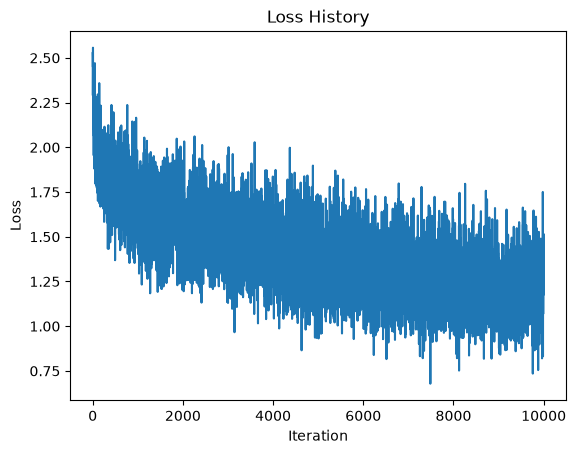

Training accuracy: 60.90%
Test accuracy: 49.26%


In [19]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ("plane", "car", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck")

# 2. Network parameters
Din = 3 * 32 * 32   # flattened CIFAR-10 image size
K = 10              # number of classes
H=100 #number of hidden units
std = 1e-2

# One layer: directly map input to output
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 0.4  # learning rate
lr_decay = 0.9      # learning rate decay
reg = 0             # regularization strength

loss_history = []

# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)                                # (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()     # (Ntr, K)

        # Forward pass
        h= torch.sigmoid(x_train.mm(w1) + b1)  # hidden layer activation
        logits = h.mm(w2) + b2                   # output layer logits
        shifted_logits = logits - torch.max(logits, dim=1, keepdim=True).values  # for numerical stability
        log_probs = shifted_logits - torch.log(torch.sum(torch.exp(shifted_logits), dim=1, keepdim=True))  # log softmax
        loss =-log_probs[torch.arange(Ntr), labels].mean() + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))  # cross-entropy loss with L2 regularization
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        probs = torch.exp(log_probs)  # softmax probabilities
        dlogits = (probs - y_train_onehot) / Ntr  # gradient of loss w.r.t. logits
        dw2 = h.t().mm(dlogits) + 2 * reg * w2  # gradient w.r.t. w2
        db2 = dlogits.sum(dim=0)  # gradient w.r.t. b2
        dh = dlogits.mm(w2.t())  # gradient w.r.t. hidden layer
        dz1=dh * h * (1 - h)  # gradient w.r.t. pre-activation of hidden layer (sigmoid derivative)
        dw1 = x_train.t().mm(dz1) + 2 * reg * w1  # gradient w.r.t. w1
        db1 = dz1.sum(dim=0)  # gradient w.r.t. b1

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5 & 6. Accuracy evaluation
def evaluate(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            h= torch.sigmoid(x.mm(w1) + b1)
            logits = h.mm(w2) + b2
            predicted = torch.argmax(logits, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


train_acc = evaluate(trainloader)
print(f"Training accuracy: {train_acc:.2f}%")

test_acc = evaluate(testloader)
print(f"Test accuracy: {test_acc:.2f}%")

In this above code by changing the learning rate from $1\times 10^{-4}$ to 0.4, the training loss decreases more rapidly, and the model converges faster. The final training and test accuracies are also higher compared to using a smaller learning rate.


### Question 2

2.11.0+cu128
Using device: cuda
Epoch 1/10 | Train Loss: 0.0988 | Test Loss: 0.0899 | Train Acc: 96.92% | Test Acc: 97.11%
Epoch 2/10 | Train Loss: 0.0591 | Test Loss: 0.0553 | Train Acc: 98.17% | Test Acc: 98.27%
Epoch 3/10 | Train Loss: 0.0374 | Test Loss: 0.0412 | Train Acc: 98.83% | Test Acc: 98.63%
Epoch 4/10 | Train Loss: 0.0340 | Test Loss: 0.0373 | Train Acc: 98.92% | Test Acc: 98.84%
Epoch 5/10 | Train Loss: 0.0232 | Test Loss: 0.0357 | Train Acc: 99.23% | Test Acc: 98.79%
Epoch 6/10 | Train Loss: 0.0262 | Test Loss: 0.0408 | Train Acc: 99.12% | Test Acc: 98.70%
Epoch 7/10 | Train Loss: 0.0162 | Test Loss: 0.0344 | Train Acc: 99.49% | Test Acc: 99.02%
Epoch 8/10 | Train Loss: 0.0168 | Test Loss: 0.0364 | Train Acc: 99.42% | Test Acc: 98.89%
Epoch 9/10 | Train Loss: 0.0115 | Test Loss: 0.0366 | Train Acc: 99.63% | Test Acc: 99.01%
Epoch 10/10 | Train Loss: 0.0095 | Test Loss: 0.0370 | Train Acc: 99.69% | Test Acc: 99.04%


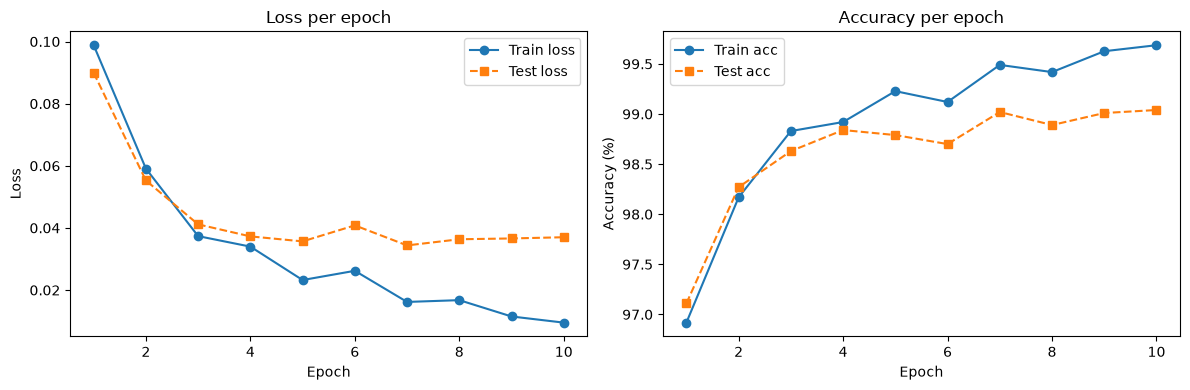

In [ ]:
import torch
print(torch.__version__)
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5,stride=1, padding=0)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5, stride=1, padding=0)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        #flatten layer
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = self.pool1(x)
        x = torch.relu(self.conv2(x))
        x = self.pool2(x)

        x = x.view(-1, 16 * 5 * 5)  # Flatten the tensor
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x
    
transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
])

# Print the NN architecture

batch_size = 50
data_root = './data'

trainset = torchvision.datasets.MNIST(root=data_root, train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root=data_root, train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = LeNet5().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


def evaluate(net, loader):
    net.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = net(data)
            loss_sum += criterion(outputs, labels).item() * labels.size(0)  # weight by batch size
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, 100 * correct / total
    
train_losses, test_losses = [], []
train_accuracies, test_accuracies = [], []

epochs = 10
for epoch in range(epochs):
    model.train()
    for data, labels in trainloader:
        data, labels = data.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(data), labels)
        loss.backward()
        optimizer.step()

    # evaluate BOTH sets the same way (eval mode, no dropout/BN updates)
    train_loss, train_acc = evaluate(model, trainloader)
    test_loss,  test_acc  = evaluate(model, testloader)

    train_losses.append(train_loss);  test_losses.append(test_loss)
    train_accuracies.append(train_acc); test_accuracies.append(test_acc)

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f} "
          f"| Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_losses, '-o', label='Train loss')
plt.plot(range(1, epochs+1), test_losses,  '--s', label='Test loss')
plt.title('Loss per epoch'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), train_accuracies, '-o', label='Train acc')
plt.plot(range(1, epochs+1), test_accuracies,  '--s', label='Test acc')
plt.title('Accuracy per epoch'); plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)'); plt.legend()
plt.tight_layout(); plt.show()

### Implementing modern CNN

2.11.0+cu128
Using device: cuda
113386 parameters
Epoch 1/10 | Train Loss: 0.0586 | Test Loss: 0.0579 | Train Acc: 98.22% | Test Acc: 98.07%
Epoch 2/10 | Train Loss: 0.0305 | Test Loss: 0.0299 | Train Acc: 99.02% | Test Acc: 99.01%
Epoch 3/10 | Train Loss: 0.0334 | Test Loss: 0.0401 | Train Acc: 98.94% | Test Acc: 98.79%
Epoch 4/10 | Train Loss: 0.0176 | Test Loss: 0.0246 | Train Acc: 99.44% | Test Acc: 99.19%
Epoch 5/10 | Train Loss: 0.0169 | Test Loss: 0.0297 | Train Acc: 99.46% | Test Acc: 99.03%
Epoch 6/10 | Train Loss: 0.0139 | Test Loss: 0.0276 | Train Acc: 99.55% | Test Acc: 99.13%
Epoch 7/10 | Train Loss: 0.0129 | Test Loss: 0.0295 | Train Acc: 99.59% | Test Acc: 99.15%
Epoch 8/10 | Train Loss: 0.0092 | Test Loss: 0.0253 | Train Acc: 99.71% | Test Acc: 99.19%
Epoch 9/10 | Train Loss: 0.0148 | Test Loss: 0.0322 | Train Acc: 99.50% | Test Acc: 99.07%
Epoch 10/10 | Train Loss: 0.0089 | Test Loss: 0.0229 | Train Acc: 99.69% | Test Acc: 99.26%


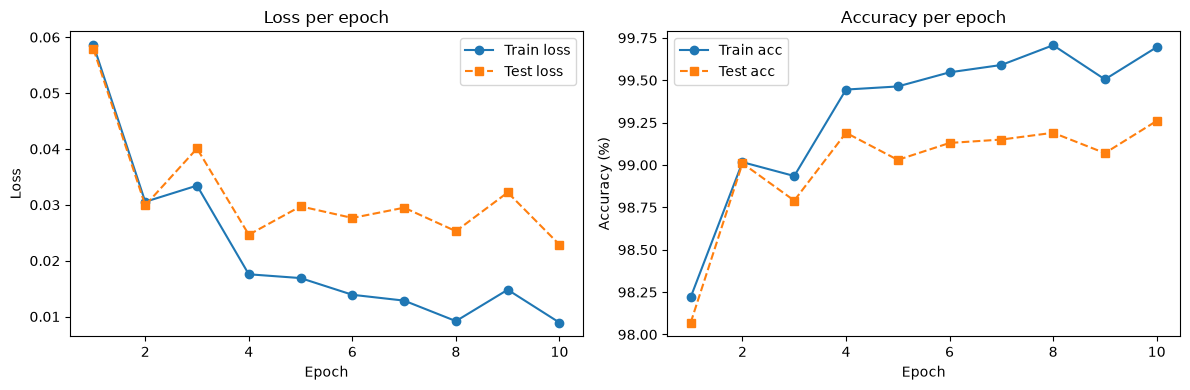

In [22]:
import torch
print(torch.__version__)
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

class NewCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1= nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1,bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block2= nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1,padding=1,bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.block3= nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1,padding=1,bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(128 *4*4, 10)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = x.view(x.size(0), -1)  # Flatten the tensor
        x = self.dropout(x)
        x = self.fc1(x)
        return x

    
transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
])

#  # instead of LeNet5()


batch_size = 50
data_root = './data'

trainset = torchvision.datasets.MNIST(root=data_root, train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root=data_root, train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model2 = NewCNN().to(device)
print(sum(p.numel() for p in model2.parameters()), "parameters")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model2.parameters(), lr=0.001)

train_losses2, test_losses2 = [], []
train_accuracies2, test_accuracies2 = [], []

def evaluate(net, loader):
    net.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = net(data)
            loss_sum += criterion(outputs, labels).item() * labels.size(0)  # weight by batch size
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, 100 * correct / total

epochs = 10
for epoch in range(epochs):
    # Implement the training loop for one epoch
    model2.train()  # Set the model to training mode
    for i, (data, labels) in enumerate(trainloader):
        data, labels = data.to(device), labels.to(device)
        
        optimizer.zero_grad()  # Zero the gradients
        outputs2 = model2(data)  # Forward pass
        loss = criterion(outputs2, labels)  # Compute loss
        loss.backward()  # Backward pass
        optimizer.step()  # Update weights

    # evaluate BOTH sets the same way (eval mode, no dropout/BN updates)
    train_loss, train_acc = evaluate(model2, trainloader)
    test_loss,  test_acc  = evaluate(model2, testloader)

    train_losses2.append(train_loss);  test_losses2.append(test_loss)
    train_accuracies2.append(train_acc); test_accuracies2.append(test_acc)

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f} "
          f"| Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_losses2, '-o', label='Train loss')
plt.plot(range(1, epochs+1), test_losses2,  '--s', label='Test loss')
plt.title('Loss per epoch'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), train_accuracies2, '-o', label='Train acc')
plt.plot(range(1, epochs+1), test_accuracies2,  '--s', label='Test acc')
plt.title('Accuracy per epoch'); plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)'); plt.legend()
plt.tight_layout(); plt.show()

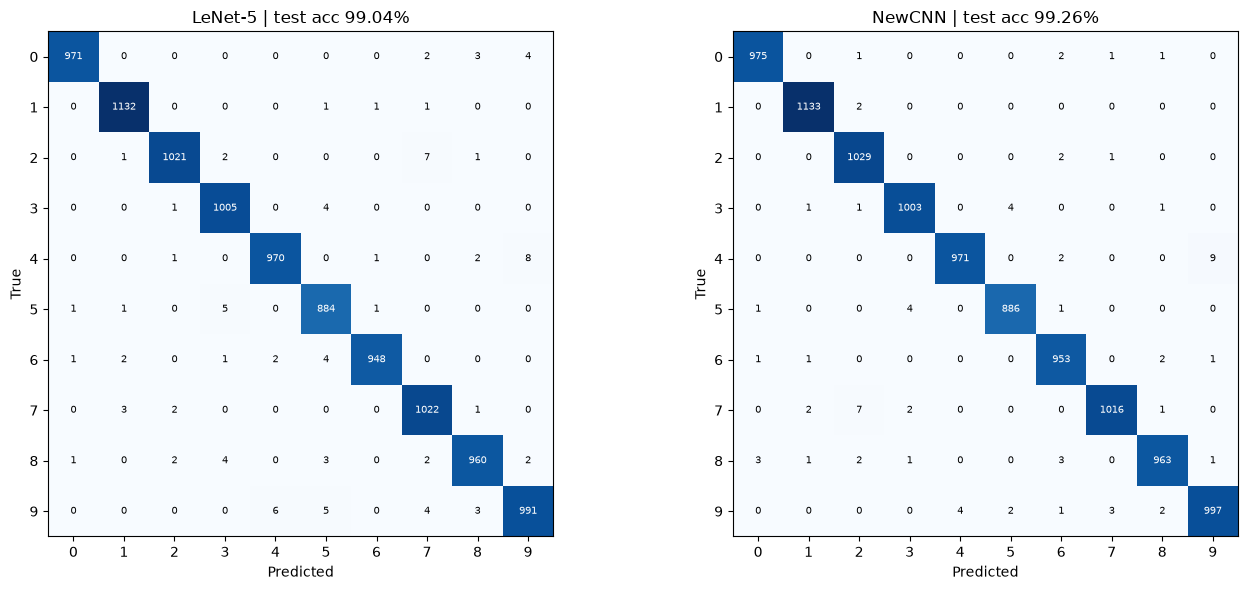

In [23]:
import numpy as np

@torch.no_grad()
def predict(net, loader):
    net.eval()
    preds, labels_all = [], []
    for data, labels in loader:
        data = data.to(device)
        preds.append(net(data).argmax(1).cpu())
        labels_all.append(labels)
    return torch.cat(preds).numpy(), torch.cat(labels_all).numpy()

def conf_matrix(preds, labels, n=10):
    cm = np.zeros((n, n), dtype=int)
    np.add.at(cm, (labels, preds), 1)   # rows = true class, cols = predicted class
    return cm

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (name, net) in zip(ax, [("LeNet-5", model), ("NewCNN", model2)]):
    p, l = predict(net, testloader)
    cm = conf_matrix(p, l)
    a.imshow(cm, cmap="Blues")
    a.set(title=f"{name} | test acc {100*(p==l).mean():.2f}%",
          xlabel="Predicted", ylabel="True", xticks=range(10), yticks=range(10))
    for i in range(10):
        for j in range(10):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()

According to the results, NewCNN ends higher, 99.26% against 99.04% test accuracy and gets there faster (98.07% after epoch 1 against 97.11%).

And also LeNet’s test loss bottoms out around epoch 7 (0.034) and then creeps up to 0.037 while its train loss keeps falling. That is mild overfitting.

Also NewCNN has 113 386 total parameters while LeNet has about 61.7k params

### Question 03

Device: cuda
Classes: ['ants', 'bees'] | train: 244 | val: 153

=== finetune | trainable params: 11,177,538 / 11,177,538 | lr: 0.001 ===
Epoch  1/15 | Train Loss: 0.2750 | Val Loss: 0.3254 | Train Acc: 92.62% | Val Acc: 92.16%
Epoch  2/15 | Train Loss: 0.1737 | Val Loss: 0.2387 | Train Acc: 93.44% | Val Acc: 92.16%
Epoch  3/15 | Train Loss: 0.0855 | Val Loss: 0.1810 | Train Acc: 98.36% | Val Acc: 93.46%
Epoch  4/15 | Train Loss: 0.0590 | Val Loss: 0.1608 | Train Acc: 99.59% | Val Acc: 93.46%
Epoch  5/15 | Train Loss: 0.0463 | Val Loss: 0.1657 | Train Acc: 99.59% | Val Acc: 94.77%
Epoch  6/15 | Train Loss: 0.0496 | Val Loss: 0.1735 | Train Acc: 99.59% | Val Acc: 93.46%
Epoch  7/15 | Train Loss: 0.0383 | Val Loss: 0.2001 | Train Acc: 99.59% | Val Acc: 92.16%
Epoch  8/15 | Train Loss: 0.0300 | Val Loss: 0.1818 | Train Acc: 100.00% | Val Acc: 92.16%
Epoch  9/15 | Train Loss: 0.0295 | Val Loss: 0.1780 | Train Acc: 100.00% | Val Acc: 92.81%
Epoch 10/15 | Train Loss: 0.0266 | Val Loss: 0.1693

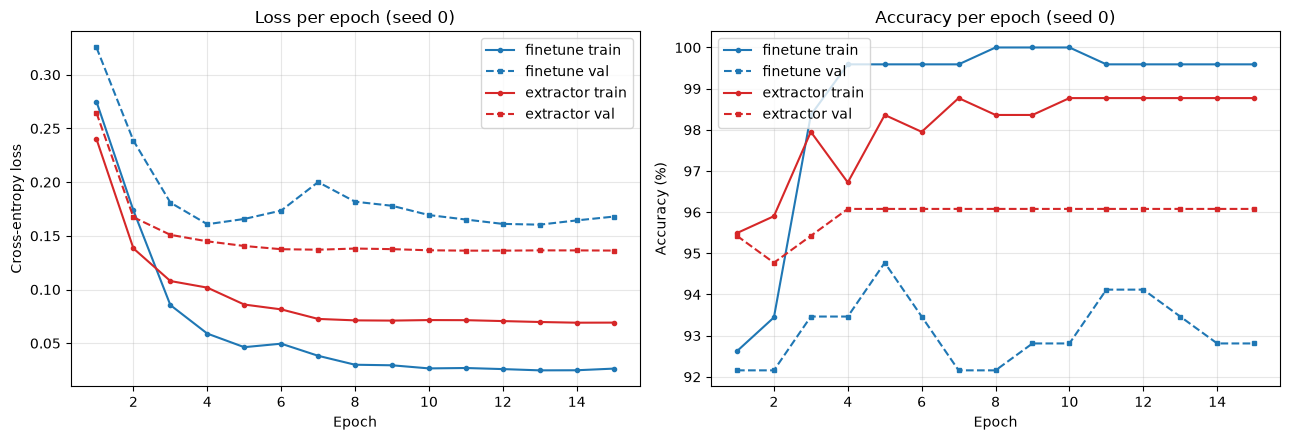

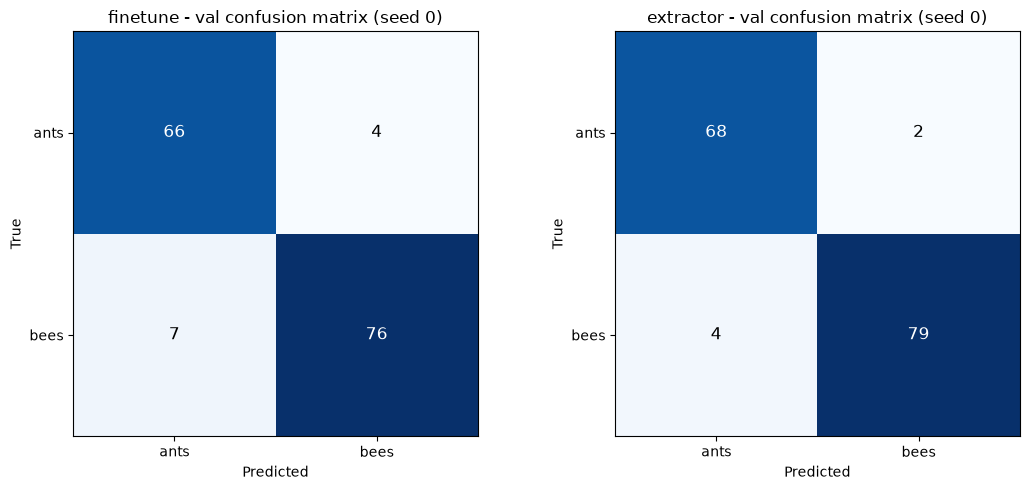

In [25]:
import copy
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision import datasets, models

EPOCHS, BATCH_SIZE = 15, 16
LR, MOMENTUM = 0.001, 0.9
STEP_SIZE, GAMMA = 7, 0.1          # StepLR: lr x0.1 every 7 epochs
SEEDS = [0, 1, 2]                  # repeat runs: val set is only 153 images

q3_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
q3_criterion = nn.CrossEntropyLoss()
print("Device:", q3_device)

DATA_DIR = "hymenoptera_data"
URL = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
if not os.path.isdir(DATA_DIR):
    print("Downloading hymenoptera dataset...")
    urllib.request.urlretrieve(URL, "hymenoptera_data.zip")
    with zipfile.ZipFile("hymenoptera_data.zip") as z:
        z.extractall(".")

q3_mean, q3_std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet stats
q3_train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(q3_mean, q3_std),
])
q3_val_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(q3_mean, q3_std),
])

q3_trainset = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), q3_train_tf)
# same images, validation transforms: used only to measure train loss/accuracy fairly
q3_trainset_eval = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), q3_val_tf)
q3_valset = datasets.ImageFolder(os.path.join(DATA_DIR, "val"), q3_val_tf)

class_names = q3_trainset.classes          # ['ants', 'bees']
q3_K = len(class_names)
print(f"Classes: {class_names} | train: {len(q3_trainset)} | val: {len(q3_valset)}")

q3_trainloader = torch.utils.data.DataLoader(q3_trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
q3_trainloader_eval = torch.utils.data.DataLoader(q3_trainset_eval, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
q3_valloader = torch.utils.data.DataLoader(q3_valset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


def q3_build_model(mode):
    net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if mode == "extractor":
        for p in net.parameters():                  # freeze the whole backbone
            p.requires_grad = False
    net.fc = nn.Linear(net.fc.in_features, q3_K)    # new head, always trainable
    return net.to(q3_device)


@torch.no_grad()
def q3_evaluate(net, loader, return_preds=False):
    net.eval()
    loss_sum, correct, total = 0.0, 0, 0
    preds_all, labels_all = [], []
    for x, y in loader:
        x, y = x.to(q3_device), y.to(q3_device)
        out = net(x)
        loss_sum += q3_criterion(out, y).item() * y.size(0)
        pred = out.argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)
        if return_preds:
            preds_all.append(pred.cpu())
            labels_all.append(y.cpu())
    loss, acc = loss_sum / total, 100 * correct / total
    if return_preds:
        return loss, acc, torch.cat(preds_all).numpy(), torch.cat(labels_all).numpy()
    return loss, acc


def q3_train(net, mode, verbose=True):
    params = [p for p in net.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=LR, momentum=MOMENTUM)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=STEP_SIZE, gamma=GAMMA)
    if verbose:
        n_train = sum(p.numel() for p in params)
        n_total = sum(p.numel() for p in net.parameters())
        print(f"\n=== {mode} | trainable params: {n_train:,} / {n_total:,} | lr: {LR} ===")

    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    for epoch in range(EPOCHS):
        # frozen backbone: keep BatchNorm statistics fixed, so use eval mode
        net.eval() if mode == "extractor" else net.train()
        for x, y in q3_trainloader:
            x, y = x.to(q3_device), y.to(q3_device)
            optimizer.zero_grad()
            loss = q3_criterion(net(x), y)
            loss.backward()
            optimizer.step()
        scheduler.step()

        # train and val measured the same way: eval mode, no augmentation
        train_loss, train_acc = q3_evaluate(net, q3_trainloader_eval)
        val_loss, val_acc = q3_evaluate(net, q3_valloader)
        for k, v in zip(hist, [train_loss, val_loss, train_acc, val_acc]):
            hist[k].append(v)
        if verbose:
            print(f"Epoch {epoch + 1:2d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} "
                  f"| Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")
    return hist


def q3_confusion_matrix(preds, labels):
    cm = np.zeros((q3_K, q3_K), dtype=int)
    np.add.at(cm, (labels, preds), 1)    # rows = true, cols = predicted
    return cm


modes = ["finetune", "extractor"]
q3_hist = {m: [] for m in modes}     # one history per seed
q3_final_val = {m: [] for m in modes}
q3_final_train = {m: [] for m in modes}
q3_cms = {}                          # confusion matrix from seed 0

for mode in modes:
    for seed in SEEDS:
        torch.manual_seed(seed)
        np.random.seed(seed)
        q3_net = q3_build_model(mode)
        h = q3_train(q3_net, mode, verbose=(seed == SEEDS[0]))   # full log for the first seed only
        q3_hist[mode].append(h)
        _, val_acc, p, l = q3_evaluate(q3_net, q3_valloader, return_preds=True)
        q3_final_val[mode].append(val_acc)
        q3_final_train[mode].append(h["train_acc"][-1])
        if seed == SEEDS[0]:
            q3_cms[mode] = q3_confusion_matrix(p, l)
        print(f"{mode} | seed {seed} | final train acc: {h['train_acc'][-1]:.2f}% | final val acc: {val_acc:.2f}%")
        del q3_net

print("\n Summary (final-epoch accuracy, mean ± std over seeds) ")
for mode in modes:
    print(f"{mode:10s} | train: {np.mean(q3_final_train[mode]):.2f} ± {np.std(q3_final_train[mode]):.2f}% "
          f"| val: {np.mean(q3_final_val[mode]):.2f} ± {np.std(q3_final_val[mode]):.2f}%  "
          f"(per seed: {', '.join(f'{a:.2f}' for a in q3_final_val[mode])})")

colors = {"finetune": "tab:blue", "extractor": "tab:red"}
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for mode in modes:
    h, c = q3_hist[mode][0], colors[mode]
    ax[0].plot(ep, h["train_loss"], "-o", color=c, markersize=3, label=f"{mode} train")
    ax[0].plot(ep, h["val_loss"], "--s", color=c, markersize=3, label=f"{mode} val")
    ax[1].plot(ep, h["train_acc"], "-o", color=c, markersize=3, label=f"{mode} train")
    ax[1].plot(ep, h["val_acc"], "--s", color=c, markersize=3, label=f"{mode} val")
ax[0].set(title="Loss per epoch (seed 0)", xlabel="Epoch", ylabel="Cross-entropy loss")
ax[1].set(title="Accuracy per epoch (seed 0)", xlabel="Epoch", ylabel="Accuracy (%)")
for a in ax:
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(q3_cms), figsize=(5.5 * len(q3_cms), 5), squeeze=False)
for a, (mode, cm) in zip(axes[0], q3_cms.items()):
    a.imshow(cm, cmap="Blues")
    a.set(title=f"{mode} - val confusion matrix (seed 0)", xlabel="Predicted", ylabel="True",
          xticks=range(q3_K), yticks=range(q3_K), xticklabels=class_names, yticklabels=class_names)
    for i in range(q3_K):
        for j in range(q3_K):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

Observations:
1. The feature extractor genaralises better than fine tuning, as the validation accuracy is higher for the extractor mode compared to the finetune mode across all seeds.
2. Also the Fine tuning overfits the traning data, as the training accuracy has reached 100%.

For a small dataset that is similar to ImageNet, feature extraction is the better choice: more accurate, more stable and cheaper. Fine-tuning would likely be better with more data, a lower learning rate for the backbone, or a larger domain shift from ImageNet